
# Exploratory Data Analysis and Diagnosis

This module dives into visualization techniques for effective Exploratory Data Analysis (EDA) with interactive visualizations. You will learn how to investigate and diagnose your time series data to test for specific assumptions such as stationarity and autocorrelation. Finally, the notebook covers practical methods for transforming your time series data using a family of power transforms, decomposition, and differencing methods.

Additionally, how decompose a time series into its components (trend, seasonality, and residuals), test for different assumptions that your models may rely on (such as stationarity, normality, and homoskedasticity), and explore techniques to transform the data to satisfy some of these assumptions.  

The recipes that you will encounter in this chapter are as follows:  
* Plotting time series data using pandas
* Plotting time series data with interactive visualizations using hvPlot


# Technical Requirements for the Chapter

In this notebook and onward, we will extensively use pandas 1.4.2 (released April 2, 2022). This applies to all the recipes in the chapter.

There are four additional libraries that we will be using:
• hvplot
• seaborn
• matplotlib


* If you are using `pip`, then you can install these packages from your terminal with the following:

```
pip install hvplot seaborn matplotlib jupyter plotly==5.5.0
```

If you are using `conda`, then you can install these packages with the following:

```
conda install -c conda-forge seaborn
conda install -c plotly plotly=5.5.0
conda install -c pyviz hvplot
```

The visualizations should work in Jupyter notebooks, but if you plan to use JupyterLab, then you will need to install an additional extension, jupyterlab_pyviz:

```
conda install jupyterlab
jupyter labextension install @pyviz/jupyterlab_pyviz
```

Throughout this notebook, you will be using three datasets (Closing Price Stock Data, CO2, and Air Passengers). The CO2 and Air Passengers datasets are provided with the statsmodels library. The Air Passengers dataset contains monthly airline passenger numbers from 1949 to 1960. The CO2 dataset contains weekly atmospheric carbon dioxide levels on Mauna Loa. The Closing Price Stock Data dataset includes Microsoft, Apple, and IBM stock prices from November 2019 to November 2021.

In [1]:
import matplotlib
matplotlib.__version__

'3.5.1'

In [2]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from statsmodels.datasets import co2, get_rdataset

#file = Path('../../datasets/Ch9/closing_price.csv')
closing_price = pd.read_csv('https://raw.githubusercontent.com/FuTSA23/time-series-analysis-datasets/main/closing_price.csv', 
                            index_col='Date',
                            parse_dates=True)
co2_df = co2.load_pandas().data
co2_df = co2_df.ffill()
air_passengers = get_rdataset("AirPassengers")
airp_df = air_passengers.data
airp_df.index = pd.date_range('1949', '1961', freq='M')
airp_df.drop(columns=['time'], inplace=True)
# store for future use
airp_df.reset_index().rename(columns={'value':'passengers', 'index':'date'}).to_csv('https://raw.githubusercontent.com/FuTSA23/time-series-analysis-datasets/main/air_passenger.csv', index=False)

In [3]:
import warnings
warnings.filterwarnings('ignore')

In [4]:
###### configurations for image quality#######
plt.rcParams["figure.figsize"] = [12, 5]   ##
# plt.rcParams['figure.dpi'] = 300           ## 300 for printing
# plt.rc('font', size=8)                     ## 
# plt.rc('axes', titlesize=16)               ## 
# plt.rc('axes', labelsize=14)               ##
# plt.rc('xtick', labelsize=10)              ##
# plt.rc('ytick', labelsize=10)              ##
# plt.rc('legend', fontsize=10)              ##
# plt.rc('figure', titlesize=12)             ## 
#############################################

# Recipe 1. Plotting Time Series Data using pandas

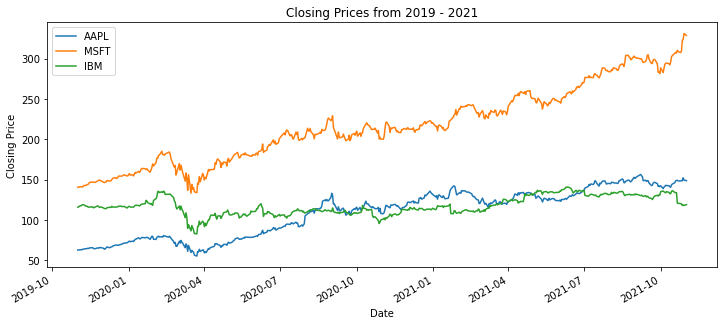

In [5]:
start_date = '2019'
end_date = '2021'
plot = closing_price.plot(
            title=f'Closing Prices from {start_date} - {end_date}',
            ylabel= 'Closing Price')
# plt.savefig('images/fig_9.1.png', bbox_inches='tight')

In this code cell, you are dividing each value in the closing_price DataFrame by the first value in the DataFrame using the div() method, and storing the result in a new DataFrame called closing_price_n. This operation is known as normalization, and it scales the data so that the first value is equal to 1 and all other values are relative to the first value.

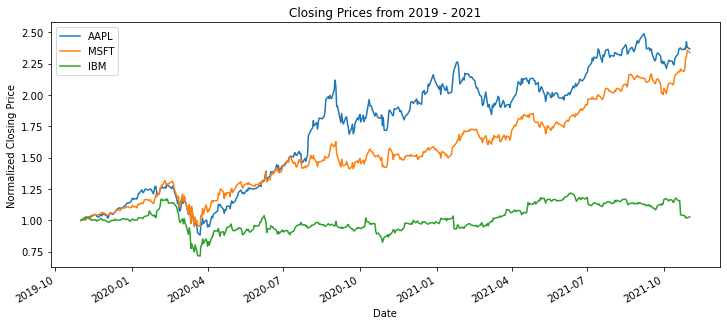

In [6]:
closing_price_n = closing_price.div(closing_price.iloc[0])
plot = closing_price_n.plot(
            title=f'Closing Prices from {start_date} - {end_date}',
            ylabel= 'Normalized Closing Price')
#plt.savefig('images/fig_9.2.png', bbox_inches='tight')

In [7]:
closing_price_n.head()

,AAPL,MSFT,IBM
Date,,,
2019-11-01,1.000000,1.000000,1.000000
2019-11-04,1.006567,1.005775,1.015790
2019-11-05,1.005121,1.005149,1.017413
2019-11-06,1.005551,1.002366,1.023980
2019-11-07,1.017156,1.003757,1.027937


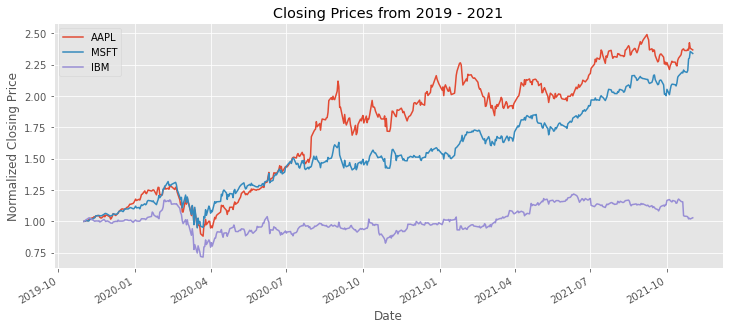

In [8]:
plt.style.use('ggplot')
plot = closing_price_n.plot(
            title=f'Closing Prices from {start_date} - {end_date}',
            ylabel= 'Normalized Closing Price')
#you can change the plot style as well as save it in your local directory
plot.get_figure().savefig('plot_1.jpg')

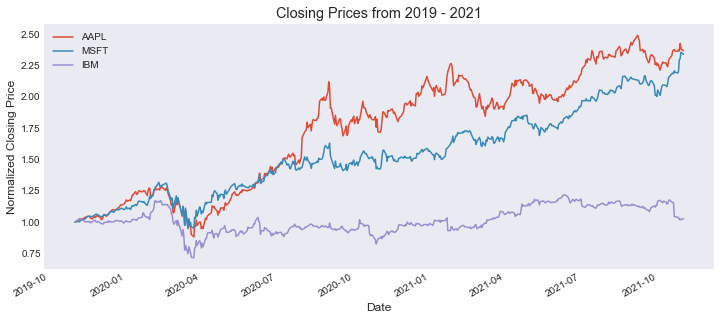

In [9]:
plt.style.use('seaborn-dark')
plot = closing_price_n.plot(
            title=f'Closing Prices from {start_date} - {end_date}',
            ylabel= 'Normalized Closing Price')

<AxesSubplot:title={'center':'Closing Prices from 2019 - 2021'}, xlabel='Date', ylabel='Normalized Closing Price'>

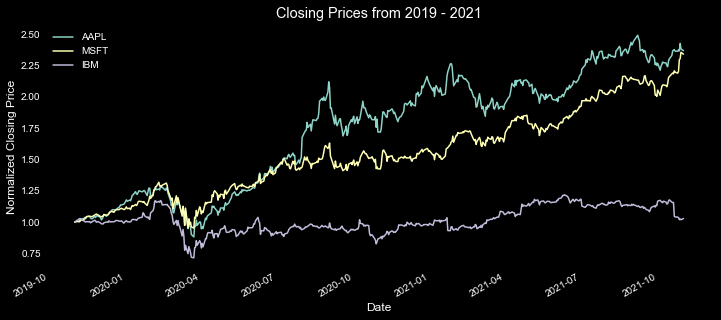

In [10]:
plt.style.use("dark_background")
plot = closing_price_n.plot(
            title=f'Closing Prices from {start_date} - {end_date}',
            ylabel= 'Normalized Closing Price')
plot

In [11]:

#plt.rcParams.update(plt.rcParamsDefault)

###### configurations for image quality#######
plt.rcParams["figure.figsize"] = [12, 5]   ##
# plt.rcParams['figure.dpi'] = 300           ##
# plt.rc('font', size=8)                     ## 
# plt.rc('axes', titlesize=16)               ## 
# plt.rc('axes', labelsize=14)               ##
# plt.rc('xtick', labelsize=10)              ##
# plt.rc('ytick', labelsize=10)              ##
# plt.rc('legend', fontsize=10)              ##
# plt.rc('figure', titlesize=12)             ## 
#############################################

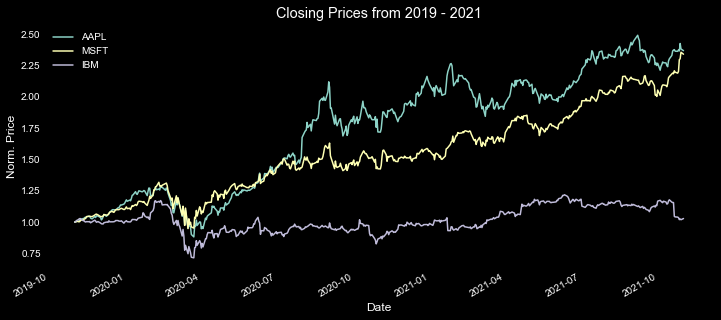

In [12]:
plot = closing_price_n.plot(
            title=f'Closing Prices from {start_date} - {end_date}',
            ylabel= 'Norm. Price')

This sectoin of code will generate a subplot for each column in the DataFrame. For the 
closing_price DataFrame, this will generate three subplots.
* The sharey parameter in the closing_price.plot function specifies whether the subplots should share the same y-axis scale. When sharey=True, all the subplots will have the same y-axis scale. When sharey=False, each subplot will have its own y-axis scale. In this code, sharey=False is set to ensure that each subplot has its own y-axis scale, which can be useful for comparing different subplots with different ranges of values.

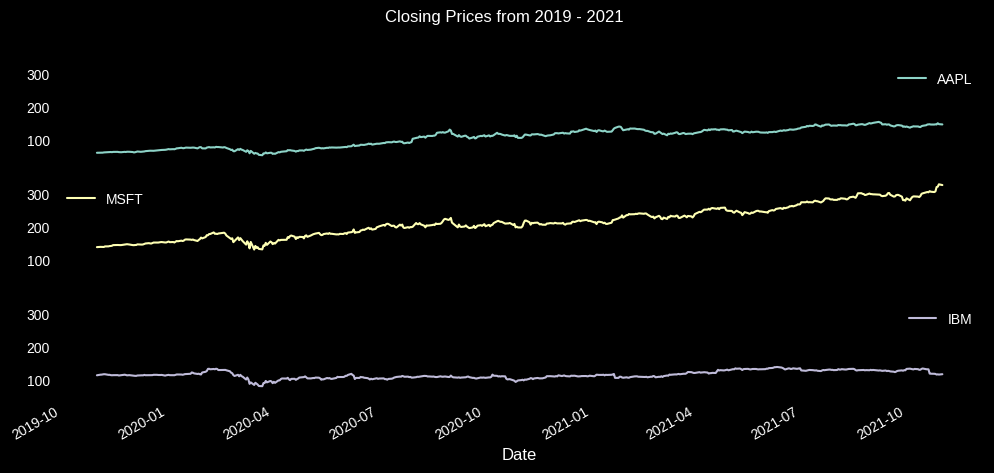

In [13]:
plot = closing_price.plot(
            subplots=True,
            sharey=True,
            sharex=True,
            title=f'Closing Prices from {start_date} - {end_date}')
#plt.savefig('images/fig_9.5.png', bbox_inches='tight')
plt.show()

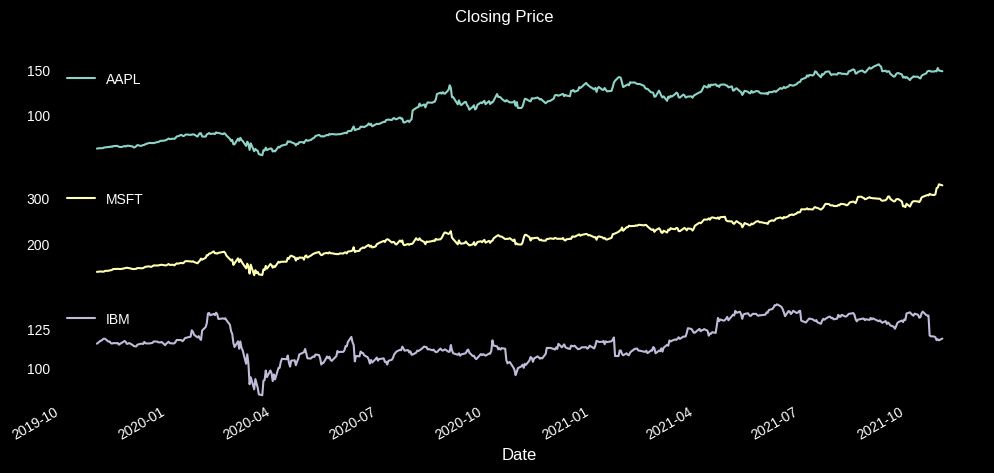

In [14]:
# with sharey = False notice the difference 
plot = closing_price.plot(
            subplots=True,
            sharey=False,
            sharex=True,
            title='Closing Price')
plt.show()


# Recipe 2. Plotting Time Series with Interactive Visualization using hvplot and Plotly Express
Here you will explore the hvPlot library to create interactive visualizations. hvPlot 
works well with pandas DataFrames to render interactive visualizations with minimal 
effort y, hvPlot allows you to render an 
interactive plot simply by substituting .plot() with .hvplot(). This can be 
useful if you have a dense chart in terms of content. You can zoom in to a specific 
portion of the chart and then, with the panning feature, move to different portions 
of the chart

In [13]:
!pip install hvplot

In [14]:
import pandas as pd
import hvplot.pandas 
import hvplot as hv
closing_price_n = closing_price.div(closing_price.iloc[0])

In [15]:
closing_price_n.head()

,AAPL,MSFT,IBM
Date,,,
2019-11-01,1.000000,1.000000,1.000000
2019-11-04,1.006567,1.005775,1.015790
2019-11-05,1.005121,1.005149,1.017413
2019-11-06,1.005551,1.002366,1.023980
2019-11-07,1.017156,1.003757,1.027937


In [16]:
plot = closing_price_n.hvplot(
    title='Time Series plot using hvplot')
plot
plt.show()

In [17]:
closing_price_n.plot(backend='hvplot', 
                     title=f'Closing Prices from {start_date} -- {end_date}')
plt.show()

In [18]:
plot = closing_price_n.plot(backend='hvplot', 
                     title=f'Closing Prices from {start_date} --- {end_date}')
plot

:NdOverlay   [Variable]
   :Curve   [Date]   (value)

* You can split each time series into separate plots per symbol (column). For example, 
to split into three columns one for each symbol (or ticker): MSFT, AAPL, and IBM. 
Subplotting can be done by specifying subplots=True
* You can also use the .cols() method for more control over the layout. The method 
allows you to control the number of plots per row. For example, .cols(1) means 
one plot per row, whereas .cols(2) indicates two plots per line

In [19]:
plot = closing_price.hvplot(width=300, subplots=True)
plt.show()

In [20]:
closing_price.hvplot(width=300, subplots=True).cols(2)


:NdLayout   [Variable]
   :Curve   [Date]   (value)

### There is more
hvPlot allows you to use two arithmetic operators, + and *, to configure the layout of 
the plots.
The plus sign (+) allows you to add two charts side by side, while multiply (*) will enable 
you to combine charts (merge one graph with another). In the following example, we will 
add two plots, so they are aligned side by side on the same row

In [21]:
closing_price['AAPL'].hvplot.line(by=['index.year'])

:NdOverlay   [index.year]
   :Curve   [Date]   (AAPL)

In [22]:
(closing_price_n['AAPL'].hvplot(width=800, height=500) + 
 closing_price_n['MSFT'].hvplot(width=800, height=500))

:Layout
   .Curve.AAPL :Curve   [Date]   (AAPL)
   .Curve.MSFT :Curve   [Date]   (MSFT)

In [23]:
(closing_price_n['AAPL'].hvplot(width=800, height=500) * 
 closing_price_n['MSFT'].hvplot())


:Overlay
   .Curve.AAPL :Curve   [Date]   (AAPL)
   .Curve.MSFT :Curve   [Date]   (MSFT)

In [24]:
(closing_price['AAPL'].hvplot(width=400) + closing_price['MSFT'].hvplot(width=400)) * closing_price['IBM'].hvplot()

:Layout
   .Overlay.I  :Overlay
      .Curve.AAPL :Curve   [Date]   (AAPL)
      .Curve.IBM  :Curve   [Date]   (IBM)
   .Overlay.II :Overlay
      .Curve.MSFT :Curve   [Date]   (MSFT)
      .Curve.IBM  :Curve   [Date]   (IBM)

In [25]:
import seaborn as sns

In [26]:
melted_cp = closing_price_n.copy().reset_index().melt(id_vars=['Date'], value_vars=closing_price_n.columns.tolist())
melted_cp.head()

,Date,variable,value
0,2019-11-01,AAPL,1.000000
1,2019-11-04,AAPL,1.006567
2,2019-11-05,AAPL,1.005121
3,2019-11-06,AAPL,1.005551
4,2019-11-07,AAPL,1.017156


In [27]:
closing_price.columns.names = ['Symbols']

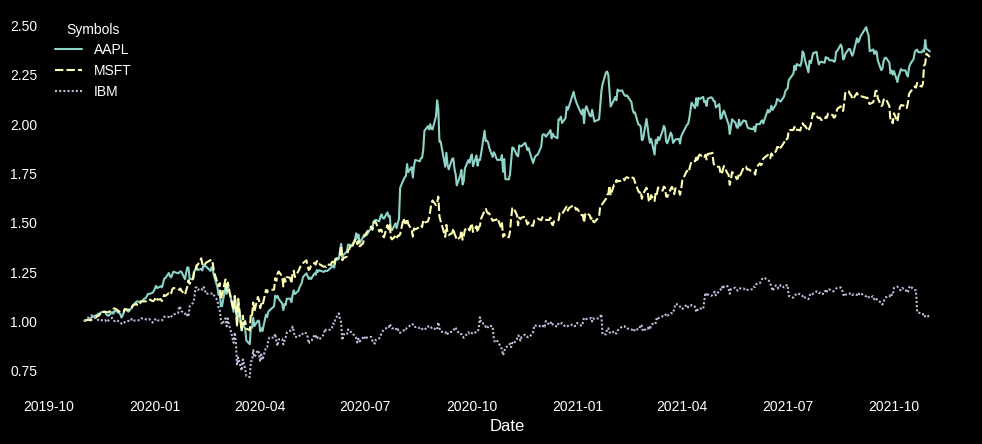

In [30]:
fig, ax = plt.subplots()
sns.lineplot(data=closing_price_n)
plt.show()